In [59]:
import pandas as pd
import numpy as np

# Set random seed for reproducibility
np.random.seed(42)

# Generate dummy data for 1000 users
n_users = 1000

user_ids = [f"USR_{i:04d}" for i in range(1, n_users + 1)]
ages = np.random.randint(21, 65, size=n_users)
annual_income = np.random.randint(30000, 150000, size=n_users)
credit_score = np.random.randint(300, 850, size=n_users)
loan_amount = np.random.randint(5000, 80000, size=n_users)
employment_status = np.random.choice(['Employed', 'Self-Employed', 'Unemployed'], size=n_users, p=[0.7, 0.2, 0.1])

# Create DataFrame with exactly 6 initial columns
df = pd.DataFrame({
    'User_ID': user_ids,
    'Age': ages,
    'Annual_Income': annual_income,
    'Credit_Score': credit_score,
    'Loan_Amount': loan_amount,
    'Employment_Status': employment_status
})

# Logic to determine the 7th column (Loan_Status)
loan_status = []
for idx, row in df.iterrows():
    if row['Employment_Status'] == 'Unemployed':
        status = 'Rejected'
    elif row['Credit_Score'] < 550:
        status = 'Rejected'
    elif row['Loan_Amount'] > (row['Annual_Income'] * 0.6):
        status = 'Rejected'
    elif row['Credit_Score'] > 700:
        status = 'Approved'
    else:
        # Probabilistic approval for medium credit scores
        status = np.random.choice(['Approved', 'Rejected'], p=[0.6, 0.4])
    loan_status.append(status)

# Add the 7th column
df['Loan_Status'] = loan_status

# Display summary details
print(f"Dataset Shape (Rows, Columns): {df.shape}")
print("\nFirst 5 rows:")
display(df.head())
print("\nLoan Status Distribution:")
print(df['Loan_Status'].value_counts())


Dataset Shape (Rows, Columns): (1000, 7)

First 5 rows:


,User_ID,Age,Annual_Income,Credit_Score,Loan_Amount,Employment_Status,Loan_Status
0,USR_0001,59,34018,669,35795,Unemployed,Rejected
1,USR_0002,49,41302,563,13770,Self-Employed,Approved
2,USR_0003,35,97506,617,16093,Employed,Rejected
3,USR_0004,63,71157,383,51571,Self-Employed,Rejected
4,USR_0005,28,84917,617,5193,Employed,Rejected



Loan Status Distribution:
Loan_Status
Rejected    740
Approved    260
Name: count, dtype: int64


In [60]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Prepare features (X) and target (y)
# We'll drop 'User_ID' as it is an identifier, and encode 'Loan_Status'
X = df_loans[['Age', 'Annual_Income', 'Credit_Score', 'Loan_Amount', 'Loan_Term_Months']]
y = df_loans['Loan_Status'].map({'Approved': 1, 'Rejected': 0})

# Split into training and testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Scale the numerical features for better convergence and performance
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Initialize and train the Logistic Regression model
log_reg = LogisticRegression(random_state=42)
log_reg.fit(X_train_scaled, y_train)

# Predict on the test set
y_pred = log_reg.predict(X_test_scaled)

# Calculate metrics
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
class_report = classification_report(y_test, y_pred, target_names=['Rejected', 'Approved'])

# Print results
print(f"Logistic Regression Model Accuracy: {accuracy:.2%}\n")
print("Confusion Matrix:")
print(conf_matrix)
print("\nClassification Report:")
print(class_report)

# Show model coefficients to understand feature importance
coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': log_reg.coef_[0]
}).sort_values(by='Coefficient', ascending=False)

print("\nFeature Coefficients:")
print(coefficients)

Logistic Regression Model Accuracy: 65.50%

Confusion Matrix:
[[66 31]
 [38 65]]

Classification Report:
              precision    recall  f1-score   support

    Rejected       0.63      0.68      0.66        97
    Approved       0.68      0.63      0.65       103

    accuracy                           0.66       200
   macro avg       0.66      0.66      0.65       200
weighted avg       0.66      0.66      0.65       200


Feature Coefficients:
            Feature  Coefficient
2      Credit_Score     1.023970
1     Annual_Income     0.586735
4  Loan_Term_Months     0.076954
0               Age     0.067003
3       Loan_Amount    -0.969909


=== Bias and Variance Analysis ===
Training Accuracy: 74.50%
Testing Accuracy:  65.50%
Accuracy Gap (Variance Indicator): 9.00%

Interpretation: High Variance (Overfitting). There is a significant gap between training and testing performance.


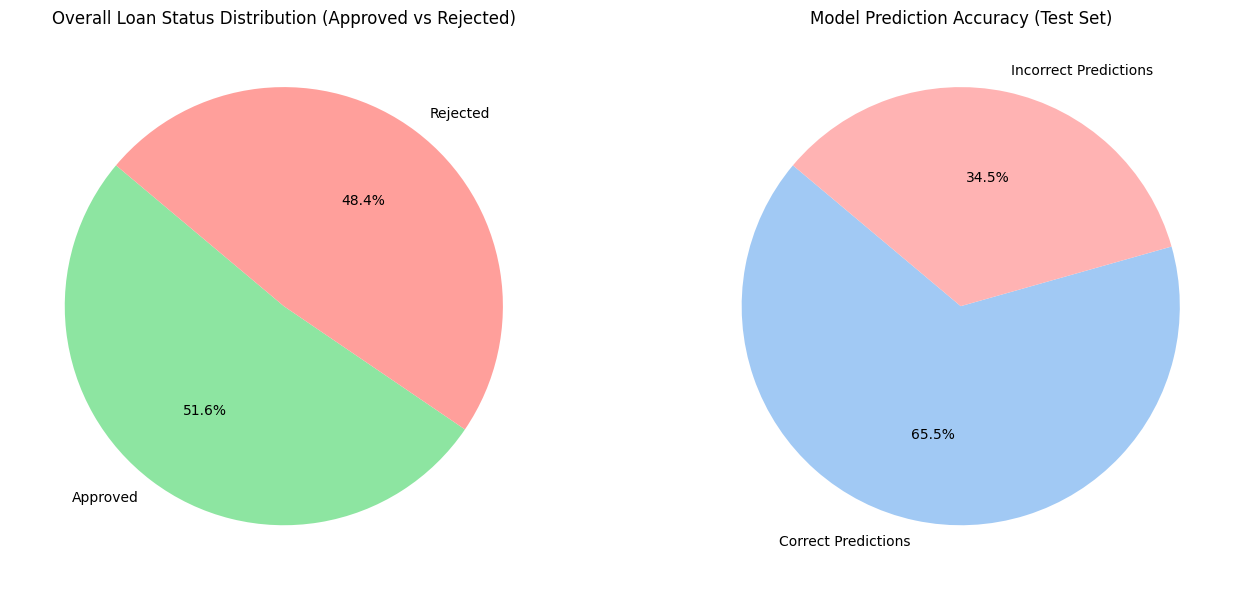

In [61]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score

# 1. Check Bias and Variance
train_acc = accuracy_score(y_train, log_reg.predict(X_train_scaled))
test_acc = accuracy

print("=== Bias and Variance Analysis ===")
print(f"Training Accuracy: {train_acc:.2%}")
print(f"Testing Accuracy:  {test_acc:.2%}")
print(f"Accuracy Gap (Variance Indicator): {abs(train_acc - test_acc):.2%}")

# Interpretation
if train_acc < 0.70:
    print("\nInterpretation: High Bias (Underfitting). Both training and testing performance are relatively low.")
elif abs(train_acc - test_acc) > 0.05:
    print("\nInterpretation: High Variance (Overfitting). There is a significant gap between training and testing performance.")
else:
    print("\nInterpretation: Balanced Model. Low variance and acceptable bias given the synthetic nature of the dataset.")

# Calculate correct and incorrect predictions for test set
correct_predictions = conf_matrix.diagonal().sum()
incorrect_predictions = len(y_test) - correct_predictions

# 2. Visualizations using Pie Charts
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Pie Chart 1: Overall Loan Status Distribution (Approved vs Rejected)
overall_counts = df_loans['Loan_Status'].value_counts()
axes[0].pie(overall_counts, labels=overall_counts.index,
            autopct='%1.1f%%', startangle=140, colors=['#8de5a1', '#ff9f9b'])
axes[0].set_title('Overall Loan Status Distribution (Approved vs Rejected)')

# Pie Chart 2: Model Prediction Performance (Correct vs Incorrect)
performance_data = [correct_predictions, incorrect_predictions]
axes[1].pie(performance_data, labels=['Correct Predictions', 'Incorrect Predictions'],
            autopct='%1.1f%%', startangle=140, colors=['#a1c9f4', '#ffb3b3'])
axes[1].set_title('Model Prediction Accuracy (Test Set)')

plt.tight_layout()
plt.show()

### Logistic Regression Modeling (80/20 Train-Test Split)
We will prepare the features, split the dataset into an 80% training set and a 20% testing set, scale the features for stable convergence, train the `LogisticRegression` model, and output the evaluation metrics.

### Test the Logistic Regression Model with Custom Inputs
Use the form fields below to adjust the features and get an instant prediction from your trained model.

In [62]:
#@title Enter Client Details for Loan Prediction { run: "auto" }

Age = 28 #@param {type:"integer"}
Annual_Income = 200000 #@param {type:"number"}
Credit_Score = 870 #@param {type:"integer"}
Loan_Amount = 100000 #@param {type:"number"}
Loan_Term_Months = 36 #@param [12, 24, 36, 48, 60] {type:"raw"}

import numpy as np
import pandas as pd

# Create a DataFrame with the custom input features
custom_data = pd.DataFrame([{
    'Age': Age,
    'Annual_Income': Annual_Income,
    'Credit_Score': Credit_Score,
    'Loan_Amount': Loan_Amount,
    'Loan_Term_Months': Loan_Term_Months
}])

# Scale the custom inputs using the pre-trained scaler
custom_data_scaled = scaler.transform(custom_data)

# Predict class and probability
prediction = log_reg.predict(custom_data_scaled)[0]
prediction_proba = log_reg.predict_proba(custom_data_scaled)[0]

# Output results
status = "Approved" if prediction == 1 else "Rejected"
probability = prediction_proba[1] if prediction == 1 else prediction_proba[0]

print("=== Prediction Results ===")
print(f"Loan Status Prediction: {status}")
print(f"Confidence: {probability:.2%}")


=== Prediction Results ===
Loan Status Prediction: Approved
Confidence: 75.63%
